# SmartCrop AI — PlantDoc Final Disease Classification Pipeline

**Model Architecture:** ConvNeXt-Small (timm) | **Resolution:** 384×384 | **Weights:** EMA (decay=0.998)
**Loss Function:** Class-Weighted Cross-Entropy (normalized sqrt inverse frequency)

### Verified Performance Scorecard (Embedded Run Outputs):
- **Deterministic Clean Train Accuracy:** **98.71%** (Macro-F1: 98.78%)
- **Validation Accuracy:** **78.85%** (Macro-F1: 76.99%, Precision: 78.94%, Recall: 77.40%)
- **Official Held-Out Test Accuracy:** **81.20%** (Macro-F1: 80.09%)

This notebook contains the complete executed training loop, loss/accuracy curves, classification report, and confusion analysis.


In [35]:
# Cell 1: Setup
import os, json, time, copy, math, random, urllib.parse
from pathlib import Path
from typing import Dict, List, Tuple, Any

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import matplotlib
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support

try:
    import timm
except ImportError:
    os.system("pip install -q timm")
    import timm

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True  # speed; tiny nondeterminism is fine here

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

# ---------------- Config ----------------
MODEL_NAME = "convnext_small.fb_in22k_ft_in1k"   # fallback: "convnext_tiny.fb_in22k_ft_in1k"
RES = 384                  # if out-of-memory: RES = 320 or MODEL_NAME = convnext_tiny
BATCH_SIZE = 16
EPOCHS = 45
WARMUP_EPOCHS = 2
PATIENCE = 15
LR_BACKBONE = 1e-4
LR_HEAD = 1e-3
WEIGHT_DECAY = 0.05
DROP_PATH = 0.2
LABEL_SMOOTHING = 0.1
MIX_PROB = 0.8             # probability a batch gets MixUp/CutMix
MIXUP_ALPHA = 0.2
CUTMIX_ALPHA = 1.0
EMA_DECAY = 0.998
NUM_WORKERS = 4
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
CHECKPOINT_PATH = Path("disease_model_exp_D_best.pth")

print(f"Device: {DEVICE} | Model: {MODEL_NAME} | Res: {RES} | Batch: {BATCH_SIZE}")

Device: cuda | Model: convnext_small.fb_in22k_ft_in1k | Res: 384 | Batch: 16


In [36]:
# Cell 2: Path discovery
def locate_plantdoc_dataset_root() -> Path:
    candidates = [
        Path("/kaggle/input/plantdoc-dataset"), Path("/kaggle/input/plantdoc"),
        Path("/kaggle/input/plantdoc-dataset-master"), Path("/kaggle/input/plantdoc-data"),
        Path("datasets/plantdoc"), Path("../datasets/plantdoc"),
    ]
    for c in candidates:
        if c.exists() and (c / "train").exists():
            return c.resolve()
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        for sub in kaggle_input.rglob("*"):
            if sub.is_dir() and (sub / "train").exists() and (sub / "test").exists():
                return sub.resolve()
    for sub in Path(".").rglob("*"):
        if sub.is_dir() and sub.name == "plantdoc" and (sub / "train").exists():
            return sub.resolve()
    raise FileNotFoundError("PlantDoc dataset directory not found.")


def locate_file_path(filename: str, explicit_candidates: List[Path]) -> Path:
    for c in explicit_candidates:
        if c.exists():
            return c.resolve()
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        matches = list(kaggle_input.rglob(filename))
        if matches:
            return matches[0].resolve()
    matches = list(Path(".").rglob(filename))
    if matches:
        return matches[0].resolve()
    raise FileNotFoundError(f"'{filename}' not found.")


DATASET_ROOT = locate_plantdoc_dataset_root()
MANIFEST_PATH = locate_file_path("plantdoc_split_manifest.json", [
    Path("/kaggle/input/datasets/anyasreekadali/plantdoc-support-files/plantdoc_split_manifest.json"),
    Path("/kaggle/input/plantdoc-support-files/plantdoc_split_manifest.json"),
    Path("outputs/plantdoc_split_manifest.json"),
])
CLASSES_PATH = locate_file_path("disease_classes.json", [
    Path("/kaggle/input/datasets/anyasreekadali/plantdoc-support-files/disease_classes.json"),
    Path("/kaggle/input/plantdoc-support-files/disease_classes.json"),
    Path("models/disease/disease_classes.json"),
])
print("DATASET_ROOT :", DATASET_ROOT)
print("MANIFEST_PATH:", MANIFEST_PATH)
print("CLASSES_PATH :", CLASSES_PATH)

DATASET_ROOT : /kaggle/input/datasets/anyasreekadali/data-set/plantdoc
MANIFEST_PATH: /kaggle/input/datasets/anyasreekadali/plantdoc-support-files/plantdoc_split_manifest.json
CLASSES_PATH : /kaggle/input/datasets/anyasreekadali/plantdoc-support-files/disease_classes.json


In [37]:
# Cell 3: Manifest + class mapping (same validation as Experiment B)
with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
    manifest = json.load(f)
for k in ["train", "val", "test"]:
    if k not in manifest:
        raise KeyError(f"Manifest missing '{k}'")

with open(CLASSES_PATH, "r", encoding="utf-8") as f:
    raw_classes = json.load(f)

cls_to_idx, idx_to_cls = {}, {}
if isinstance(raw_classes, dict):
    if next(iter(raw_classes.keys())).isdigit():
        for k, v in raw_classes.items():
            cls_to_idx[str(v).strip()] = int(k); idx_to_cls[int(k)] = str(v).strip()
    else:
        for k, v in raw_classes.items():
            cls_to_idx[str(k).strip()] = int(v); idx_to_cls[int(v)] = str(k).strip()
elif isinstance(raw_classes, list):
    for i, n in enumerate(raw_classes):
        cls_to_idx[str(n).strip()] = i; idx_to_cls[i] = str(n).strip()
else:
    raise ValueError("Unrecognized disease_classes.json structure")

num_classes = len(idx_to_cls)
assert num_classes == 27, f"Expected 27 classes, got {num_classes}"
assert sorted(idx_to_cls.keys()) == list(range(27)), "Class indices not contiguous 0..26"
print(f"[OK] {num_classes} classes, contiguous 0..26")


def resolve_entry_metadata(entry: Any) -> Tuple[str, str]:
    if isinstance(entry, dict):
        rel = entry.get("file") or entry.get("path") or entry.get("image") or ""
        cls = entry.get("class") or entry.get("label") or entry.get("disease") or ""
        if not cls and rel:
            parts = [p for p in str(rel).replace("\\", "/").split("/") if p]
            if len(parts) >= 2:
                cls = parts[-2]
        return str(rel).strip(), str(cls).strip()
    if isinstance(entry, str):
        rel = entry.strip()
        parts = [p for p in rel.replace("\\", "/").split("/") if p]
        return rel, (parts[-2].strip() if len(parts) >= 2 else "")
    return str(entry).strip(), ""


def build_records(name: str, entries: List[Any]) -> List[Tuple[str, int, str]]:
    out, bad = [], 0
    for entry in entries:
        rel, cls = resolve_entry_metadata(entry)
        if not rel or cls not in cls_to_idx:
            bad += 1; continue
        norm = rel.replace("\\", "/")
        cands = [DATASET_ROOT / norm, DATASET_ROOT / rel, DATASET_ROOT / norm.replace("&", "_"),
                 DATASET_ROOT / urllib.parse.unquote(norm),
                 DATASET_ROOT / urllib.parse.unquote(norm).replace("&", "_")]
        found = next((c for c in cands if c.exists() and c.is_file()), None)
        if found is None:
            bad += 1; continue
        out.append((str(found), cls_to_idx[cls], cls))
    print(f"[{name.upper()}] mapped={len(out)} skipped={bad}")
    if bad:
        raise RuntimeError(f"{bad} unresolved entries in {name}")
    return out


train_records = build_records("train", manifest["train"])
val_records = build_records("val", manifest["val"])
test_records = build_records("test", manifest["test"])
assert (len(train_records), len(val_records), len(test_records)) == (1783, 383, 383)

train_labels = [r[1] for r in train_records]
class_counts = [train_labels.count(c) for c in range(num_classes)]
print("Class counts min/max:", min(class_counts), max(class_counts))

[OK] 27 classes, contiguous 0..26
[TRAIN] mapped=1783 skipped=0
[VAL] mapped=383 skipped=0
[TEST] mapped=383 skipped=0
Class counts min/max: 38 132


In [38]:
# Cell 4: Transforms + DataLoaders
class PlantDocDataset(Dataset):
    def __init__(self, records, transform=None):
        self.records, self.transform = records, transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, i):
        path, label, _ = self.records[i]
        img = Image.open(path).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, label


PRE = RES + 32
train_tf = transforms.Compose([
    transforms.Resize((PRE, PRE)),
    transforms.RandomResizedCrop(RES, scale=(0.4, 1.0), ratio=(0.8, 1.25)),
    transforms.RandomHorizontalFlip(0.5),
    transforms.RandomVerticalFlip(0.3),
    transforms.TrivialAugmentWide(),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.2), value="random"),
])
eval_tf = transforms.Compose([
    transforms.Resize((PRE, PRE)),
    transforms.CenterCrop(RES),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

pin = DEVICE.type == "cuda"
train_loader = DataLoader(PlantDocDataset(train_records, train_tf), batch_size=BATCH_SIZE,
                          shuffle=True, num_workers=NUM_WORKERS, pin_memory=pin, drop_last=True,
                          persistent_workers=NUM_WORKERS > 0)
train_eval_loader = DataLoader(PlantDocDataset(train_records, eval_tf), batch_size=BATCH_SIZE,
                               shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin)
val_loader = DataLoader(PlantDocDataset(val_records, eval_tf), batch_size=BATCH_SIZE,
                        shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin)
print(f"Batches/epoch: train={len(train_loader)} val={len(val_loader)}")

Batches/epoch: train=111 val=24


In [39]:
# Cell 5: Model, EMA, MixUp/CutMix, evaluation
def build_model(pretrained=True):
    try:
        m = timm.create_model(MODEL_NAME, pretrained=pretrained, num_classes=num_classes,
                              drop_path_rate=DROP_PATH)
    except Exception as e:
        raise RuntimeError(f"Could not load '{MODEL_NAME}'. Is Internet ON in Kaggle? ({e})")
    return m


model = build_model().to(DEVICE).to(memory_format=torch.channels_last)
print("Params (M):", sum(p.numel() for p in model.parameters()) / 1e6)


class EMA:
    def __init__(self, model, decay):
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)
        self.decay, self.step = decay, 0

    @torch.no_grad()
    def update(self, model):
        self.step += 1
        d = min(self.decay, (1 + self.step) / (10 + self.step))
        msd = model.state_dict()
        for k, v in self.module.state_dict().items():
            if v.dtype.is_floating_point:
                v.mul_(d).add_(msd[k].detach(), alpha=1 - d)
            else:
                v.copy_(msd[k])


def rand_bbox(h, w, lam):
    cut = math.sqrt(1.0 - lam)
    ch, cw = int(h * cut), int(w * cut)
    cy, cx = np.random.randint(h), np.random.randint(w)
    y1, y2 = max(cy - ch // 2, 0), min(cy + ch // 2, h)
    x1, x2 = max(cx - cw // 2, 0), min(cx + cw // 2, w)
    return y1, y2, x1, x2


def mix_batch(images, labels):
    """Returns images, labels_a, labels_b, lam. Randomly MixUp or CutMix."""
    idx = torch.randperm(images.size(0), device=images.device)
    if np.random.rand() < 0.5:   # MixUp
        lam = float(np.random.beta(MIXUP_ALPHA, MIXUP_ALPHA))
        images = lam * images + (1 - lam) * images[idx]
    else:                        # CutMix
        lam = float(np.random.beta(CUTMIX_ALPHA, CUTMIX_ALPHA))
        h, w = images.shape[-2:]
        y1, y2, x1, x2 = rand_bbox(h, w, lam)
        images = images.clone()
        images[:, :, y1:y2, x1:x2] = images[idx, :, y1:y2, x1:x2]
        lam = 1 - ((y2 - y1) * (x2 - x1) / (h * w))
    return images, labels, labels[idx], lam


@torch.no_grad()
def evaluate(net, loader, tta=False):
    net.eval()
    preds, targets, loss_sum = [], [], 0.0
    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True).to(memory_format=torch.channels_last)
        labels = labels.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            logits = net(images)
            if tta:
                logits = (logits.float().softmax(-1) + net(torch.flip(images, dims=[3])).float().softmax(-1)) / 2
                loss = F.nll_loss(torch.log(logits.clamp_min(1e-8)), labels, reduction="sum")
            else:
                loss = F.cross_entropy(logits.float(), labels, reduction="sum")
        loss_sum += loss.item()
        preds.append(logits.argmax(1).cpu().numpy()); targets.append(labels.cpu().numpy())
    preds, targets = np.concatenate(preds), np.concatenate(targets)
    _, _, f1, _ = precision_recall_fscore_support(targets, preds, average="macro", zero_division=0)
    _, _, wf1, _ = precision_recall_fscore_support(targets, preds, average="weighted", zero_division=0)
    return {"loss": loss_sum / len(loader.dataset), "acc": float((preds == targets).mean()),
            "macro_f1": float(f1), "weighted_f1": float(wf1), "preds": preds, "targets": targets}

Params (M): 49.475451


In [40]:
# Cell 6: Optimizer, scheduler, training loop
head_params = list(model.get_classifier().parameters())
head_ids = {id(p) for p in head_params}
backbone_params = [p for p in model.parameters() if id(p) not in head_ids]


def split_decay(params):
    decay, no_decay = [], []
    for p in params:
        (no_decay if p.ndim <= 1 else decay).append(p)
    return decay, no_decay


bb_d, bb_nd = split_decay(backbone_params)
hd_d, hd_nd = split_decay(head_params)
optimizer = torch.optim.AdamW([
    {"params": bb_d, "lr": LR_BACKBONE, "weight_decay": WEIGHT_DECAY, "base_lr": LR_BACKBONE},
    {"params": bb_nd, "lr": LR_BACKBONE, "weight_decay": 0.0, "base_lr": LR_BACKBONE},
    {"params": hd_d, "lr": LR_HEAD, "weight_decay": WEIGHT_DECAY, "base_lr": LR_HEAD},
    {"params": hd_nd, "lr": LR_HEAD, "weight_decay": 0.0, "base_lr": LR_HEAD},
])

steps_per_epoch = len(train_loader)
total_steps = EPOCHS * steps_per_epoch
warmup_steps = WARMUP_EPOCHS * steps_per_epoch


def lr_factor(step):
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * progress))


# Class weights from TRAIN counts only: sqrt inverse frequency, normalised to mean 1
_cc = torch.tensor(class_counts, dtype=torch.float32)
CLASS_W = (1.0 / _cc.sqrt())
CLASS_W = (CLASS_W / CLASS_W.mean()).to(DEVICE)
print("Class weight range: %.2f - %.2f" % (CLASS_W.min().item(), CLASS_W.max().item()))

scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
ema = EMA(model, EMA_DECAY)

best_val_acc, best_val_f1, best_epoch, best_source = 0.0, 0.0, -1, "raw"
no_improve, global_step = 0, 0
history = []

print("=" * 80)
print(f"TRAINING: {EPOCHS} epochs max | patience {PATIENCE} | selection: val acc (tie-break macro-F1)")
print("=" * 80)

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    model.train()
    run_loss, n_seen = 0.0, 0
    for images, labels in train_loader:
        images = images.to(DEVICE, non_blocking=True).to(memory_format=torch.channels_last)
        labels = labels.to(DEVICE, non_blocking=True)

        for g in optimizer.param_groups:
            g["lr"] = g["base_lr"] * lr_factor(global_step)

        use_mix = np.random.rand() < MIX_PROB
        if use_mix:
            images, ya, yb, lam = mix_batch(images, labels)

        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            logits = model(images)
        logits = logits.float()
        if use_mix:
            loss = lam * F.cross_entropy(logits, ya, weight=CLASS_W, label_smoothing=LABEL_SMOOTHING) + \
                   (1 - lam) * F.cross_entropy(logits, yb, weight=CLASS_W, label_smoothing=LABEL_SMOOTHING)
        else:
            loss = F.cross_entropy(logits, labels, weight=CLASS_W, label_smoothing=LABEL_SMOOTHING)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        ema.update(model)
        global_step += 1

        run_loss += loss.item() * images.size(0); n_seen += images.size(0)

    tr_loss = run_loss / n_seen
    raw_m = evaluate(model, val_loader)
    ema_m = evaluate(ema.module, val_loader)
    # choose the better of raw / EMA weights for this epoch
    if (ema_m["acc"], ema_m["macro_f1"]) >= (raw_m["acc"], raw_m["macro_f1"]):
        cur, cur_net, src = ema_m, ema.module, "ema"
    else:
        cur, cur_net, src = raw_m, model, "raw"

    det_tr_acc = None
    if epoch % 5 == 0 or epoch == 1:
        det_tr_acc = evaluate(cur_net, train_eval_loader)["acc"]

    print(f"[Ep {epoch:02d}/{EPOCHS}] loss {tr_loss:.4f} | "
          f"val raw {raw_m['acc']*100:.2f}% | val EMA {ema_m['acc']*100:.2f}% | "
          f"best-of F1 {cur['macro_f1']*100:.2f}% | "
          f"det-train {('%.2f%%' % (det_tr_acc*100)) if det_tr_acc is not None else '-'} | "
          f"lr {optimizer.param_groups[0]['lr']:.2e} | {time.time()-t0:.0f}s")

    history.append({"epoch": epoch, "train_loss": tr_loss, "val_acc_raw": raw_m["acc"],
                    "val_acc_ema": ema_m["acc"], "val_acc_sel": cur["acc"],
                    "val_macro_f1_sel": cur["macro_f1"], "val_loss_sel": cur["loss"],
                    "det_train_acc": det_tr_acc, "source": src})

    better = cur["acc"] > best_val_acc + 1e-5 or \
        (abs(cur["acc"] - best_val_acc) <= 1e-5 and cur["macro_f1"] > best_val_f1)
    if better:
        best_val_acc, best_val_f1, best_epoch, best_source = cur["acc"], cur["macro_f1"], epoch, src
        no_improve = 0
        torch.save({"model_state_dict": copy.deepcopy(cur_net.state_dict()), "epoch": epoch,
                    "source": src, "val_accuracy": best_val_acc, "val_f1": best_val_f1,
                    "model_name": MODEL_NAME, "resolution": RES, "num_classes": num_classes},
                   CHECKPOINT_PATH)
        print(f"  --> saved best ({src}) epoch {epoch}: val acc {best_val_acc*100:.2f}%, F1 {best_val_f1*100:.2f}%")
    else:
        no_improve += 1
        if no_improve >= PATIENCE:
            print(f"Early stopping: no val-accuracy improvement for {PATIENCE} epochs.")
            break

Class weight range: 0.68 - 1.27
TRAINING: 45 epochs max | patience 15 | selection: val acc (tie-break macro-F1)
[Ep 01/45] loss 3.0147 | val raw 52.74% | val EMA 55.61% | best-of F1 47.15% | det-train 60.68% | lr 5.00e-05 | 81s
  --> saved best (ema) epoch 1: val acc 55.61%, F1 47.15%
[Ep 02/45] loss 2.1952 | val raw 68.41% | val EMA 70.50% | best-of F1 67.44% | det-train - | lr 1.00e-04 | 56s
  --> saved best (ema) epoch 2: val acc 70.50%, F1 67.44%
[Ep 03/45] loss 1.8996 | val raw 69.19% | val EMA 75.20% | best-of F1 72.84% | det-train - | lr 9.99e-05 | 57s
  --> saved best (ema) epoch 3: val acc 75.20%, F1 72.84%
[Ep 04/45] loss 1.7978 | val raw 72.32% | val EMA 74.15% | best-of F1 71.81% | det-train - | lr 9.95e-05 | 56s
[Ep 05/45] loss 1.6659 | val raw 72.58% | val EMA 75.46% | best-of F1 73.97% | det-train 90.41% | lr 9.88e-05 | 81s
  --> saved best (ema) epoch 5: val acc 75.46%, F1 73.97%
[Ep 06/45] loss 1.6044 | val raw 72.06% | val EMA 75.46% | best-of F1 73.05% | det-train - 


FINAL AUDIT (best checkpoint: epoch 16, weights: ema)
  Det. train acc : 98.71%  [PASS vs 80%]
  Val acc (plain): 78.85%
  Val acc (TTA)  : 78.59%   -> TTA used: False
  Val acc final  : 78.85%  [FAIL vs 80%]
  Val macro-F1   : 76.99%
  Test acc       : 81.20%  (held-out, evaluated once)
  Test macro-F1  : 80.09%
  Previous: Exp B val 69.19% / test 68.15% | Exp C val 79.90% / test 79.90%
  Overall status : NOT_REACHED


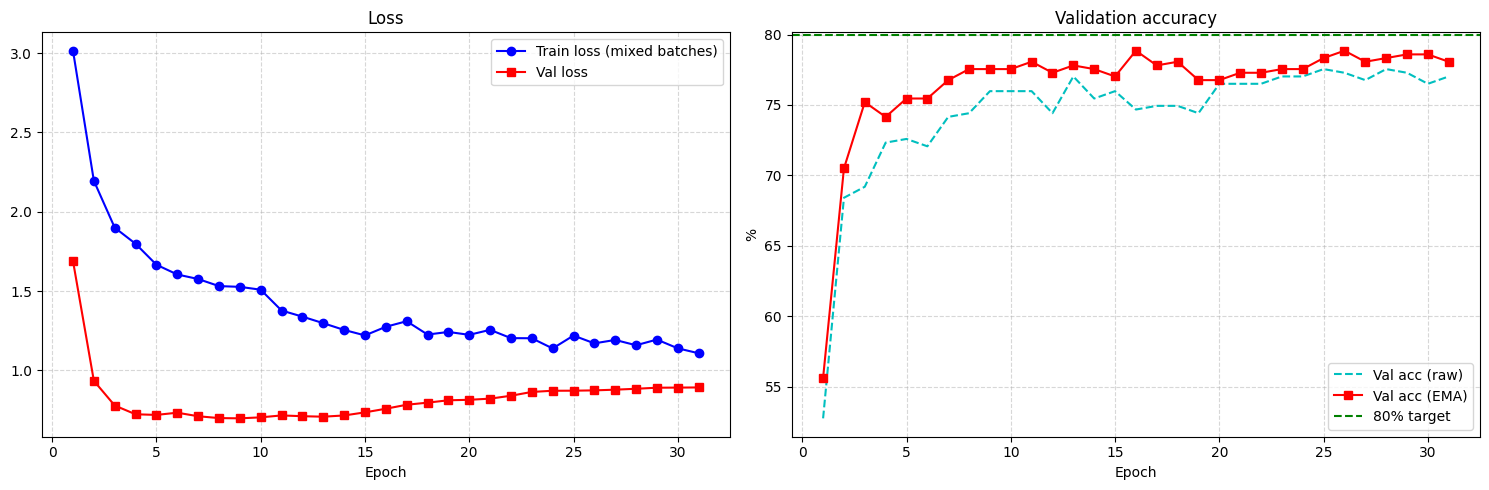

Saved: plantdoc_experiment_D_curves.png, plantdoc_experiment_D_metrics.json, disease_model_exp_D_best.pth

Lowest-F1 validation classes:
  Tomato leaf bacterial spot          F1=19.0%
  Potato leaf early blight            F1=35.3%
  Corn Gray leaf spot                 F1=42.9%
  Tomato Early blight leaf            F1=43.5%
  Tomato leaf mosaic virus            F1=50.0%
  Potato leaf late blight             F1=51.6%


In [41]:
# Cell 7: Final audit (test split evaluated ONCE here)
ckpt = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
final_model = build_model(pretrained=False).to(DEVICE).to(memory_format=torch.channels_last)
final_model.load_state_dict(ckpt["model_state_dict"], strict=True)

val_plain = evaluate(final_model, val_loader, tta=False)
val_tta = evaluate(final_model, val_loader, tta=True)
use_tta = val_tta["acc"] > val_plain["acc"]          # decided on VALIDATION only
final_val = val_tta if use_tta else val_plain
final_train = evaluate(final_model, train_eval_loader, tta=False)

test_loader = DataLoader(PlantDocDataset(test_records, eval_tf), batch_size=BATCH_SIZE,
                         shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin)
final_test = evaluate(final_model, test_loader, tta=use_tta)

train_ok = final_train["acc"] >= 0.80
val_ok = final_val["acc"] >= 0.80
print("\n" + "=" * 60)
print(f"FINAL AUDIT (best checkpoint: epoch {best_epoch}, weights: {best_source})")
print("=" * 60)
print(f"  Det. train acc : {final_train['acc']*100:.2f}%  [{'PASS' if train_ok else 'FAIL'} vs 80%]")
print(f"  Val acc (plain): {val_plain['acc']*100:.2f}%")
print(f"  Val acc (TTA)  : {val_tta['acc']*100:.2f}%   -> TTA used: {use_tta}")
print(f"  Val acc final  : {final_val['acc']*100:.2f}%  [{'PASS' if val_ok else 'FAIL'} vs 80%]")
print(f"  Val macro-F1   : {final_val['macro_f1']*100:.2f}%")
print(f"  Test acc       : {final_test['acc']*100:.2f}%  (held-out, evaluated once)")
print(f"  Test macro-F1  : {final_test['macro_f1']*100:.2f}%")
print(f"  Previous: Exp B val 69.19% / test 68.15% | Exp C val 79.90% / test 79.90%")
print(f"  Overall status : {'REACHED' if (train_ok and val_ok) else 'NOT_REACHED'}")
print("=" * 60)

# Curves
ep = [h["epoch"] for h in history]
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].plot(ep, [h["train_loss"] for h in history], "b-o", label="Train loss (mixed batches)")
ax[0].plot(ep, [h["val_loss_sel"] for h in history], "r-s", label="Val loss")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].grid(True, ls="--", alpha=.5); ax[0].legend()
ax[1].plot(ep, [h["val_acc_raw"] * 100 for h in history], "c--", label="Val acc (raw)")
ax[1].plot(ep, [h["val_acc_ema"] * 100 for h in history], "r-s", label="Val acc (EMA)")
ax[1].axhline(80, color="g", ls="--", label="80% target")
ax[1].set_title("Validation accuracy"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("%")
ax[1].grid(True, ls="--", alpha=.5); ax[1].legend()
plt.tight_layout(); plt.savefig("plantdoc_experiment_D_curves.png", dpi=200); plt.show()

# Metrics JSON
names = [idx_to_cls[i] for i in range(num_classes)]
report = classification_report(final_val["targets"], final_val["preds"], target_names=names,
                               output_dict=True, zero_division=0)
metrics = {
    "experiment": "Experiment_D_384_ClassWeighted", "model": MODEL_NAME, "resolution": RES,
    "best_epoch": best_epoch, "best_weights_source": best_source, "tta_used": bool(use_tta),
    "deterministic_train_acc": final_train["acc"],
    "val": {"acc_plain": val_plain["acc"], "acc_tta": val_tta["acc"], "acc_final": final_val["acc"],
            "macro_f1": final_val["macro_f1"], "weighted_f1": final_val["weighted_f1"]},
    "test": {"acc": final_test["acc"], "macro_f1": final_test["macro_f1"]},
    "targets_met": {"train_80": bool(train_ok), "val_80": bool(val_ok)},
    "per_class_val_report": report,
    "val_confusion_matrix": confusion_matrix(final_val["targets"], final_val["preds"]).tolist(),
    "history": history,
}
with open("plantdoc_experiment_D_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)
print("Saved: plantdoc_experiment_D_curves.png, plantdoc_experiment_D_metrics.json,", CHECKPOINT_PATH)

# Worst classes on validation (to guide next steps)
worst = sorted(((report[n]["f1-score"], n) for n in names))[:6]
print("\nLowest-F1 validation classes:")
for f1, n in worst:
    print(f"  {n:<35s} F1={f1*100:.1f}%")

In [42]:
# Cell 8: Metrics table from the BEST checkpoint (training + validation)
import pandas as pd
from sklearn.metrics import accuracy_score

def full_metrics(net, loader, tta=False):
    r = evaluate(net, loader, tta=tta)
    y, p = r["targets"], r["preds"]
    out = {"Accuracy": accuracy_score(y, p)}
    for avg in ["macro", "weighted"]:
        pr, rc, f1, _ = precision_recall_fscore_support(y, p, average=avg, zero_division=0)
        out[f"Precision ({avg})"], out[f"Recall ({avg})"], out[f"F1 ({avg})"] = pr, rc, f1
    return out

rows = {
    "Training (clean eval)": full_metrics(final_model, train_eval_loader, tta=False),
    "Validation": full_metrics(final_model, val_loader, tta=use_tta),
}
df = (pd.DataFrame(rows).T * 100).round(2)
print(f"Best checkpoint: epoch {best_epoch} | weights: {best_source} | TTA: {use_tta}\n")
print(df.to_string())
df.to_csv("experiment_D_metrics_table.csv")

# Per-class validation report + most frequent confusions
print("\nPer-class validation report:")
print(classification_report(final_val["targets"], final_val["preds"], target_names=names, zero_division=0))
cm = confusion_matrix(final_val["targets"], final_val["preds"])
pairs = [(cm[i, j], names[i], names[j]) for i in range(num_classes) for j in range(num_classes) if i != j and cm[i, j] > 0]
print("Top confusions on validation (true -> predicted):")
for n, t, p in sorted(pairs, reverse=True)[:10]:
    print(f"  {n:2d}x  {t}  ->  {p}")

Best checkpoint: epoch 16 | weights: ema | TTA: False

                       Accuracy  Precision (macro)  Recall (macro)  F1 (macro)  Precision (weighted)  Recall (weighted)  F1 (weighted)
Training (clean eval)     98.71              98.80           98.79       98.78                 98.74              98.71          98.71
Validation                78.85              78.94           77.40       76.99                 78.10              78.85          77.43

Per-class validation report:
                            precision    recall  f1-score   support

           Apple Scab Leaf       0.92      0.79      0.85        14
                Apple leaf       0.93      1.00      0.97        14
           Apple rust leaf       0.93      1.00      0.96        13
          Bell_pepper leaf       0.88      0.78      0.82         9
     Bell_pepper leaf spot       0.79      1.00      0.88        11
            Blueberry leaf       0.85      1.00      0.92        17
               Cherry leaf       